# Air Quality — Machine Learning Project

**Version 2 — Working Notebook**

**Dataset:** [UCI Air Quality](https://archive.ics.uci.edu/dataset/360/air+quality)  
**Target:** `CO(GT)` — carbon monoxide concentration.

## 1. Imports and Setup

In [4]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns

## 2. Load the Original Dataset

In [5]:
DATA_URL = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

with urlopen(DATA_URL, timeout=60) as response:
    data_bytes = response.read()

with ZipFile(BytesIO(data_bytes)) as archive:
    csv_path = next(
        (name for name in archive.namelist() if name.endswith("AirQualityUCI.csv")),
        None,
    )
    if csv_path is None:
        raise FileNotFoundError("AirQualityUCI.csv was not found in the UCI archive")

    with archive.open(csv_path) as csv_file:
        raw_df = pd.read_csv(
            csv_file,
            sep=";",
            decimal=",",
            na_values=[-200, "-200"],
        )

print("Raw dataset shape:", raw_df.shape)
display(raw_df.head())


Raw dataset shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 3. Initial Data Inspection

In [6]:
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         7674 non-null   float64
 3   PT08.S1(CO)    8991 non-null   float64
 4   NMHC(GT)       914 non-null    float64
 5   C6H6(GT)       8991 non-null   float64
 6   PT08.S2(NMHC)  8991 non-null   float64
 7   NOx(GT)        7718 non-null   float64
 8   PT08.S3(NOx)   8991 non-null   float64
 9   NO2(GT)        7715 non-null   float64
 10  PT08.S4(NO2)   8991 non-null   float64
 11  PT08.S5(O3)    8991 non-null   float64
 12  T              8991 non-null   float64
 13  RH             8991 non-null   float64
 14  AH             8991 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), str(2)
memory usage: 1.4 MB


In [7]:
display(raw_df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,11/03/2004,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18.00.00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),7674.0,NaN,NaN,NaN,2.15275,1.453252,0.1,1.1,1.8,2.9,11.9
PT08.S1(CO),8991.0,NaN,NaN,NaN,1099.833166,217.080037,647.0,937.0,1063.0,1231.0,2040.0
NMHC(GT),914.0,NaN,NaN,NaN,218.811816,204.459921,7.0,67.0,150.0,297.0,1189.0
C6H6(GT),8991.0,NaN,NaN,NaN,10.083105,7.44982,0.1,4.4,8.2,14.0,63.7
PT08.S2(NMHC),8991.0,NaN,NaN,NaN,939.153376,266.831429,383.0,734.5,909.0,1116.0,2214.0
NOx(GT),7718.0,NaN,NaN,NaN,246.896735,212.979168,2.0,98.0,180.0,326.0,1479.0
PT08.S3(NOx),8991.0,NaN,NaN,NaN,835.493605,256.81732,322.0,658.0,806.0,969.5,2683.0
NO2(GT),7715.0,NaN,NaN,NaN,113.091251,48.370108,2.0,78.0,109.0,142.0,340.0


In [8]:
print("Columns:", raw_df.columns.tolist())
print("Duplicate rows:", raw_df.duplicated().sum())


Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']
Duplicate rows: 113


## 4. Initial Data Cleaning

### 4.1 Identify Empty Rows and Columns

In [11]:
# Check completely empty rows
print("Empty rows:", raw_df.isna().all(axis=1).sum())

# Check completely empty columns
print("Empty columns:")
print(raw_df.columns[raw_df.isna().all()].tolist())

Empty rows: 114
Empty columns:
['Unnamed: 15', 'Unnamed: 16']


### 4.2 Remove Completely Empty Rows and Columns

In [12]:
df = raw_df.copy()

df = df.dropna(axis=0, how="all")
df = df.dropna(axis=1, how="all")

print("Shape after cleaning:", df.shape)

Shape after cleaning: (9357, 15)


### 4.3 Parse and Validate Timestamps

In [13]:
df["timestamp"] = pd.to_datetime(
    df["Date"] + " " +
    df["Time"].str.replace(".", ":", regex=False),
    format="%d/%m/%Y %H:%M:%S",
    errors="raise"
)

df = df.sort_values("timestamp").reset_index(drop=True)

df[["Date", "Time", "timestamp"]].head()

,Date,Time,timestamp
0,10/03/2004,18.00.00,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2004-03-10 21:00:00
4,10/03/2004,22.00.00,2004-03-10 22:00:00


In [14]:
print("Missing timestamps:", df["timestamp"].isna().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())

Missing timestamps: 0
Duplicate timestamps: 0
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


In [16]:
df = df.sort_values("timestamp").reset_index(drop=True)
df["timestamp"].is_monotonic_increasing

True

## 5. Exploratory Data Analysis (EDA)

### 5.1 Missing Values Analysis

Inspect the amount, timing, and overlap of missing measurements before deciding how to handle missing features during modeling.

In [17]:
missing_analysis = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing (%)",
    ascending=False
)

display(missing_analysis)


,Missing Count,Missing (%)
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
C6H6(GT),366,3.91
PT08.S2(NMHC),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91


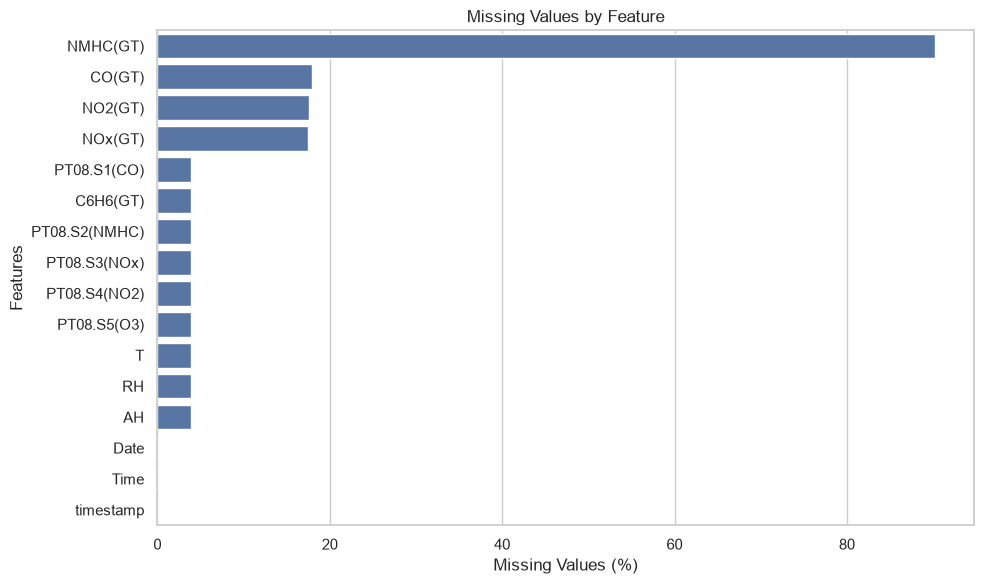

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=missing_analysis.reset_index(),
    x="Missing (%)",
    y="index"
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [19]:
columns = ["NMHC(GT)", "CO(GT)", "NOx(GT)", "NO2(GT)"]

monthly_missing = (
    df.set_index("timestamp")[columns]
    .isna()
    .resample("MS")
    .mean()
    .mul(100)
    .round(2)
)

display(monthly_missing)

,NMHC(GT),CO(GT),NOx(GT),NO2(GT)
timestamp,,,,
2004-03-01,20.20,3.53,4.31,4.31
2004-04-01,29.72,31.25,32.50,32.50
2004-05-01,99.87,20.43,19.62,19.62
2004-06-01,100.00,10.56,9.86,10.00
2004-07-01,100.00,25.00,4.30,4.44
2004-08-01,100.00,35.89,32.53,32.66
2004-09-01,100.00,22.78,38.33,38.33
2004-10-01,100.00,47.18,47.98,47.98
2004-11-01,100.00,5.69,8.61,8.61


In [20]:
missing_flags = df[
    ["CO(GT)", "NOx(GT)", "NO2(GT)"]
].isna()

display(missing_flags.corr().round(3))

,CO(GT),NOx(GT),NO2(GT)
CO(GT),1.000,0.682,0.681
NOx(GT),0.682,1.000,0.999
NO2(GT),0.681,0.999,1.000


In [21]:
nox_missing = df["NOx(GT)"].isna()
no2_missing = df["NO2(GT)"].isna()

print("Different missingness patterns:",
      (nox_missing != no2_missing).sum())

Different missingness patterns: 3


#### Missing Values — Key Findings

- Missing values exhibit a strong temporal pattern rather than being uniformly distributed across the dataset.
- `NMHC(GT)` has approximately 90% missing values, with virtually no observations available after May 2004. This makes it a strong candidate for exclusion from modeling.
- The target variable, `CO(GT)`, has substantial missingness during certain months, particularly October 2004.
- `NOx(GT)` and `NO2(GT)` show similar monthly missingness patterns, suggesting possible simultaneous measurement gaps.
- Missing-value handling should account for the temporal structure of the dataset to avoid data leakage and misleading model evaluation.

#### Missingness Correlation — Key Finding

The missingness indicators of NOx(GT) and NO2(GT) are almost perfectly correlated (0.999), indicating that missing observations occur at nearly identical timestamps.

CO(GT) also shows a positive association with the missingness of NOx(GT) (0.682) and NO2(GT) (0.681).

These findings suggest shared patterns of missing measurements, although their underlying cause cannot be determined from correlation alone.

### 5.2 Temporal Analysis

Inspect hourly observations and the daily and hourly CO patterns. The separate `time_view` is used for the raw timeline; the cleaned `df` remains available for the other analyses.

#### 5.2.1 Observed CO Over Time

In [22]:
time_view = raw_df.dropna(subset=["Date", "Time"]).copy()
time_view["timestamp"] = pd.to_datetime(
    time_view["Date"].astype(str) + " "
    + time_view["Time"].astype(str).str.replace(".", ":", regex=False),
    format="%d/%m/%Y %H:%M:%S",
    errors="raise",
)
time_view = time_view.sort_values("timestamp").reset_index(drop=True)

print("First timestamp:", time_view["timestamp"].min())
print("Last timestamp: ", time_view["timestamp"].max())
print("Duplicate timestamps:", time_view["timestamp"].duplicated().sum())
display(time_view[["timestamp", "CO(GT)"]].head())


First timestamp: 2004-03-10 18:00:00
Last timestamp:  2005-04-04 14:00:00
Duplicate timestamps: 0


,timestamp,CO(GT)
0,2004-03-10 18:00:00,2.6
1,2004-03-10 19:00:00,2.0
2,2004-03-10 20:00:00,2.2
3,2004-03-10 21:00:00,2.2
4,2004-03-10 22:00:00,1.6


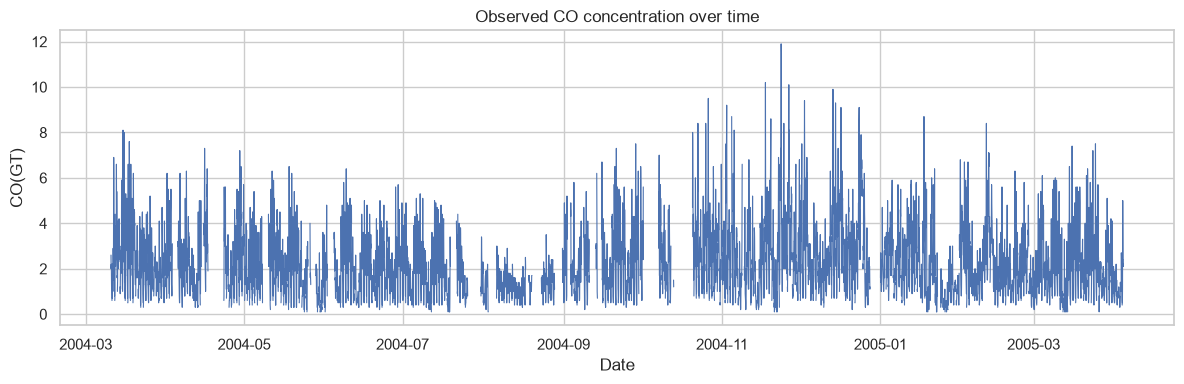

In [23]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_view["timestamp"], time_view["CO(GT)"], linewidth=0.8)
ax.set(title="Observed CO concentration over time", xlabel="Date", ylabel="CO(GT)")
plt.tight_layout()
plt.show()


#### 5.2.2 Daily CO Concentration and Observation Coverage

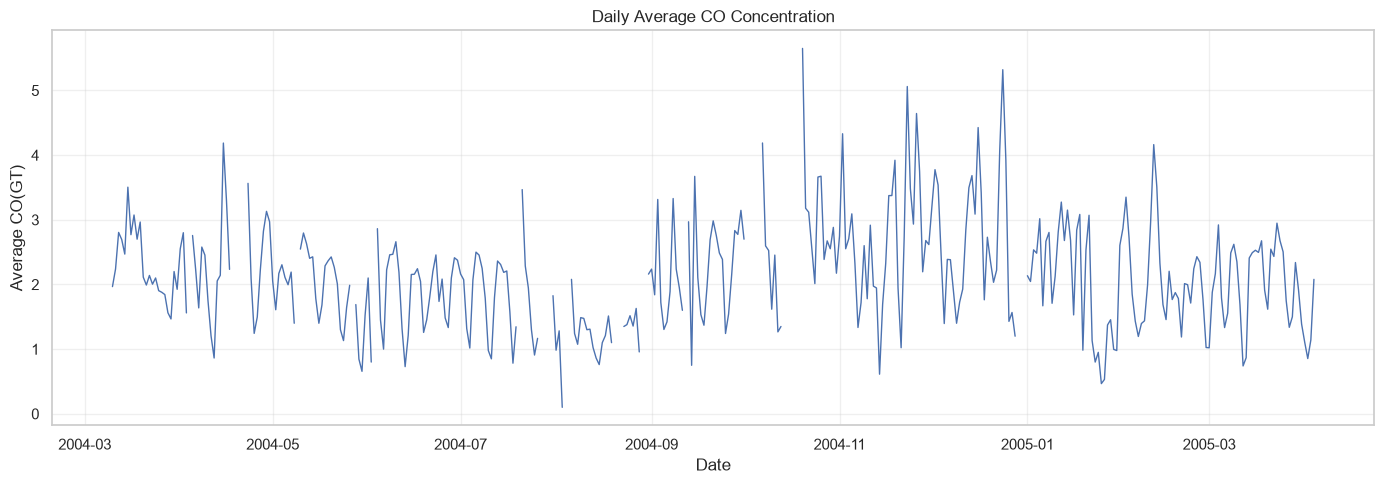

In [24]:
daily_co = (
    df.set_index("timestamp")["CO(GT)"]
    .resample("D")
    .agg(["mean", "count"])
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    daily_co.index,
    daily_co["mean"],
    linewidth=1
)

ax.set(
    title="Daily Average CO Concentration",
    xlabel="Date",
    ylabel="Average CO(GT)"
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
print("Days with 24 observations:",
      (daily_co["count"] == 24).sum())

print("Days with fewer than 24 observations:",
      ((daily_co["count"] > 0) & (daily_co["count"] < 24)).sum())

print("Days with no observations:",
      (daily_co["count"] == 0).sum())

display(daily_co["count"].describe())

Days with 24 observations: 157
Days with fewer than 24 observations: 198
Days with no observations: 36


count    391.000000
mean      19.626598
std        7.903826
min        0.000000
25%       22.000000
50%       23.000000
75%       24.000000
max       24.000000
Name: count, dtype: float64

#### 5.2.3 Hourly CO Concentration

In [26]:
# Does CO concentration vary depending on the hour of the day?
hourly_co = (
    df.groupby(df["timestamp"].dt.hour)["CO(GT)"]
    .agg(["mean", "count"])
)

display(hourly_co)

,mean,count
timestamp,,
0,1.786018,329
1,1.467802,323
2,1.099063,320
3,0.888462,312
4,0.758659,179
5,0.712934,317
6,0.921562,320
7,1.810903,321
8,2.823750,320


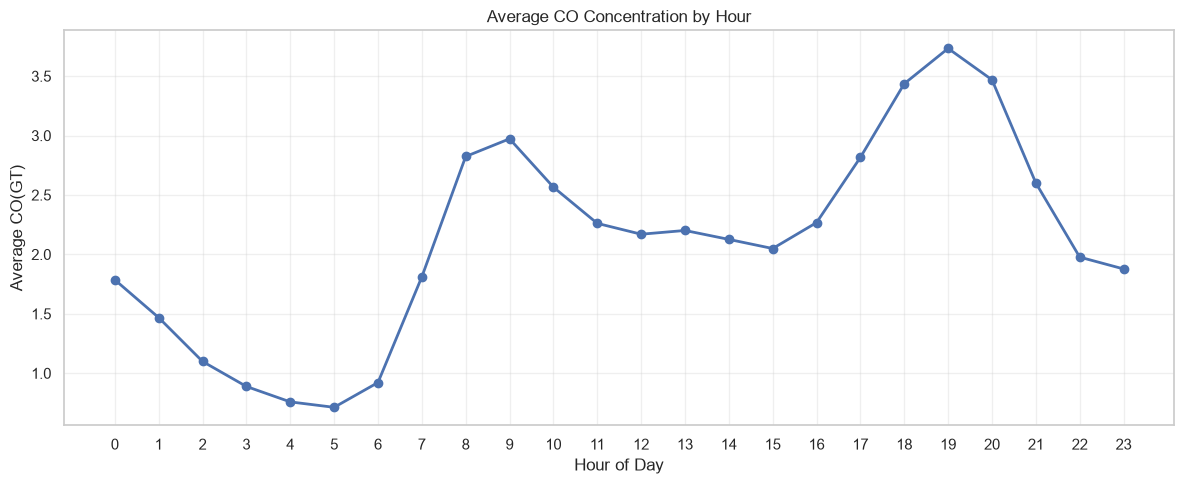

In [27]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    hourly_co.index,
    hourly_co["mean"],
    marker="o",
    linewidth=2
)

ax.set(
    title="Average CO Concentration by Hour",
    xlabel="Hour of Day",
    ylabel="Average CO(GT)"
)

ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Hourly CO Concentration — Key Findings

- CO concentration exhibits a clear bimodal daily pattern, with peaks around 9 AM and 7 PM.
- The highest average concentration occurs in the evening, while the lowest occurs around 5 AM.
- This pattern may be associated with daily human activities, including traffic, although causality cannot be established from the available data.
- Hour of day may be a useful predictive feature and should be evaluated during feature engineering.
- Differences in observation counts across hours should be examined before drawing stronger conclusions.

#### 5.2.4 Missing CO Measurements at 4 AM

In [29]:
four_am = df[df["timestamp"].dt.hour == 4].copy()

four_am["month"] = four_am["timestamp"].dt.to_period("M")

four_am_missing = (
    four_am.groupby("month")["CO(GT)"]
    .agg(["size", "count"])
)

four_am_missing["Missing %"] = (
    (1 - four_am_missing["count"] / four_am_missing["size"])
    * 100
).round(2)

display(four_am_missing)

,size,count,Missing %
month,,,
2004-03,21,5,76.19
2004-04,30,9,70.00
2004-05,31,0,100.00
2004-06,30,18,40.00
2004-07,31,16,48.39
2004-08,31,15,51.61
2004-09,30,17,43.33
2004-10,31,5,83.87
2004-11,30,19,36.67


##### Hour-Specific Missingness — Key Findings

- CO measurements at 4 AM exhibit substantial missingness (54.1%) across the observation period.
- Missingness is particularly high in May 2004 (100%) and October 2004 (83.87%).
- This pattern suggests that missing observations are associated with the hour of day, although the underlying cause remains unknown.
- The lower observation coverage at 4 AM should be considered when interpreting hourly concentration patterns.

### 5.3 Feature Relationships and Correlation Analysis

In [30]:
numeric_df = df.select_dtypes(include="number")

co_correlation = (
    numeric_df.corr()["CO(GT)"]
    .drop("CO(GT)")
    .sort_values(ascending=False)
)

display(co_correlation)

C6H6(GT)         0.931078
PT08.S2(NMHC)    0.915514
NMHC(GT)         0.889734
PT08.S1(CO)      0.879288
PT08.S5(O3)      0.854182
NOx(GT)          0.795028
NO2(GT)          0.683343
PT08.S4(NO2)     0.630703
RH               0.048890
AH               0.048556
T                0.022109
PT08.S3(NOx)    -0.703446
Name: CO(GT), dtype: float64

In [31]:
target = "CO(GT)"

correlation_summary = pd.DataFrame({
    "Correlation": co_correlation,
    "Observations": [
        df[[target, col]].dropna().shape[0]
        for col in co_correlation.index
    ]
})

correlation_summary = correlation_summary.reindex(
    correlation_summary["Correlation"]
    .abs()
    .sort_values(ascending=False)
    .index
)

display(correlation_summary)

,Correlation,Observations
C6H6(GT),0.931078,7344
PT08.S2(NMHC),0.915514,7344
NMHC(GT),0.889734,890
PT08.S1(CO),0.879288,7344
PT08.S5(O3),0.854182,7344
NOx(GT),0.795028,7261
PT08.S3(NOx),-0.703446,7344
NO2(GT),0.683343,7258
PT08.S4(NO2),0.630703,7344
RH,0.048890,7344


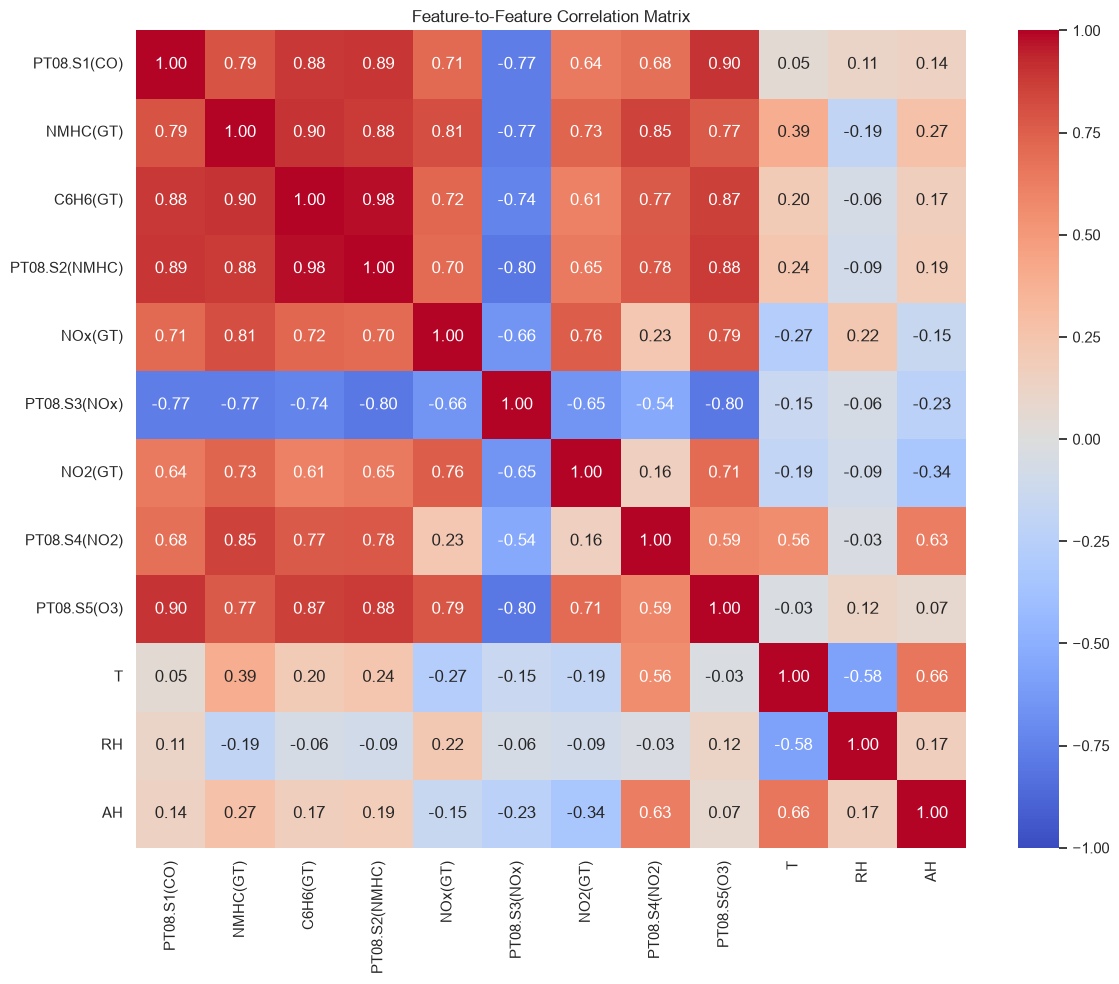

In [32]:
features_corr = (
    df.select_dtypes(include="number")
    .drop(columns=["CO(GT)"])
    .corr()
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    features_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Feature-to-Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 6. Define the Learning Task and Data Split

### 6.1 Target and Features

In [33]:
target = "CO(GT)"

excluded_columns = [
    "Date", "Time", "timestamp",
    "CO(GT)", "NMHC(GT)"
]

features = df.columns.drop(excluded_columns).tolist()

print("Target:", target)
print("Features:", features)
print("Number of features:", len(features))

Target: CO(GT)
Features: ['PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Number of features: 11


### 6.2 Chronological Train / Validation / Test Split

In [34]:
# Chronological Train / Validation / Test Split
df = df.sort_values("timestamp").reset_index(drop=True)

train_end = int(len(df) * 0.70)
val_end = int(len(df) * 0.80)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(subset)} rows | "
        f"{subset['timestamp'].min()} to "
        f"{subset['timestamp'].max()}"
    )

Train: 6549 rows | 2004-03-10 18:00:00 to 2004-12-08 14:00:00
Validation: 936 rows | 2004-12-08 15:00:00 to 2005-01-16 14:00:00
Test: 1872 rows | 2005-01-16 15:00:00 to 2005-04-04 14:00:00


### 6.3 Prepare Input and Target Sets for Time-Series Cross-Validation

In [36]:
# Remove rows with missing target values
train_df = train_df.dropna(subset=[target])
val_df = val_df.dropna(subset=[target])
test_df = test_df.dropna(subset=[target])

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

In [37]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

## 7. Data Preprocessing

### 7.1 Missing-Feature Diagnostics by Split

In [38]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nMissing feature values:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

Training: (5066, 11) (5066,)
Validation: (827, 11) (827,)
Testing: (1781, 11) (1781,)

Missing feature values:
Train: 1692
Validation: 1240
Test: 867


In [39]:
missing_by_split = pd.DataFrame({
    "Train (%)": X_train.isna().mean() * 100,
    "Validation (%)": X_val.isna().mean() * 100,
    "Test (%)": X_test.isna().mean() * 100
})

missing_by_split = missing_by_split.round(2)

display(
    missing_by_split.sort_values(
        "Validation (%)",
        ascending=False
    )
)

,Train (%),Validation (%),Test (%)
PT08.S1(CO),2.27,15.72,4.77
C6H6(GT),2.27,15.72,4.77
PT08.S2(NMHC),2.27,15.72,4.77
PT08.S3(NOx),2.27,15.72,4.77
PT08.S4(NO2),2.27,15.72,4.77
PT08.S5(O3),2.27,15.72,4.77
T,2.27,15.72,4.77
RH,2.27,15.72,4.77
AH,2.27,15.72,4.77
NOx(GT),6.45,4.23,2.86


In [40]:
for name, X in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    missing_rows = X.isna().any(axis=1)

    print(
        f"{name}: {missing_rows.sum()} rows "
        f"({missing_rows.mean():.2%}) "
        "with at least one missing feature"
    )

Train: 440 rows (8.69%) with at least one missing feature
Validation: 160 rows (19.35%) with at least one missing feature
Test: 133 rows (7.47%) with at least one missing feature


In [41]:
sensor_group = [
    "PT08.S1(CO)", "C6H6(GT)",
    "PT08.S2(NMHC)", "PT08.S3(NOx)",
    "PT08.S4(NO2)", "PT08.S5(O3)",
    "T", "RH", "AH"
]

for name, X in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    missing = X[sensor_group].isna()

    print(f"\n{name}")
    print("All 9 missing:", missing.all(axis=1).sum())
    print("At least 1 missing:", missing.any(axis=1).sum())


Train
All 9 missing: 115
At least 1 missing: 115

Validation
All 9 missing: 130
At least 1 missing: 130

Test
All 9 missing: 85
At least 1 missing: 85


### 7.2 Preprocessing Pipelines

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [43]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

## 8. Modeling and Evaluation

### 8.1 Time-Series Cross-Validation: Linear Regression vs Random Forest

In [44]:
from sklearn.model_selection import cross_validate

models = {
    "Linear Regression": linear_pipeline,
    "Random Forest": rf_pipeline
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    })

cv_summary = pd.DataFrame(cv_results)

display(cv_summary.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,0.327,0.458,0.878
1,Random Forest,0.286,0.405,0.906


### 8.2 Random Forest Validation Performance

In [45]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_model = clone(rf_pipeline)
best_model.fit(X_train, y_train)

val_predictions = best_model.predict(X_val)

print("Validation Results")
print("MAE:", round(mean_absolute_error(y_val, val_predictions), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_predictions)), 3))
print("R²:", round(r2_score(y_val, val_predictions), 3))

Validation Results
MAE: 0.567
RMSE: 0.877
R²: 0.696


### 8.3 Validation Performance by Sensor Availability

In [46]:
missing_group = X_val[sensor_group].isna().all(axis=1)

for name, mask in [
    ("Complete sensor group", ~missing_group),
    ("All 9 features missing", missing_group)
]:
    actual = y_val.loc[mask]
    predicted = val_predictions[mask.to_numpy()]

    print(f"\n{name}: {len(actual)} samples")
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print("RMSE:", round(
        np.sqrt(mean_squared_error(actual, predicted)), 3
    ))
    print("R²:", round(r2_score(actual, predicted), 3))


Complete sensor group: 697 samples
MAE: 0.47
RMSE: 0.69
R²: 0.785

All 9 features missing: 130 samples
MAE: 1.088
RMSE: 1.529
R²: 0.336


In [47]:
remaining_features = ["NOx(GT)", "NO2(GT)"]

for name, X in [
    ("Train", X_train),
    ("Validation", X_val)
]:
    # Rows where all nine sensor-related features are missing
    missing_group = X[sensor_group].isna().all(axis=1)

    # Count remaining available measurements
    available = (
        X.loc[missing_group, remaining_features]
        .notna()
        .sum(axis=1)
    )

    print(f"\n{name}")
    print("Both available:", (available == 2).sum())
    print("Only one available:", (available == 1).sum())
    print("Neither available:", (available == 0).sum())


Train
Both available: 110
Only one available: 0
Neither available: 5

Validation
Both available: 125
Only one available: 0
Neither available: 5


### 8.4 Fallback Ridge Experiments

#### 8.4.1 Ridge Trained on Missing-Sensor Cases

In [48]:
# Experiment with a Fallback Model
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

remaining_features = ["NOx(GT)", "NO2(GT)"]

# Identify rows with all nine features missing
train_missing_9 = X_train[sensor_group].isna().all(axis=1)
val_missing_9 = X_val[sensor_group].isna().all(axis=1)

# Keep only rows where NOx and NO2 are available
train_fallback = (
    train_missing_9 &
    X_train[remaining_features].notna().all(axis=1)
)

val_fallback = (
    val_missing_9 &
    X_val[remaining_features].notna().all(axis=1)
)

# Train the fallback model
fallback_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

fallback_model.fit(
    X_train.loc[train_fallback, remaining_features],
    y_train.loc[train_fallback]
)

# Predict on validation samples
fallback_predictions = fallback_model.predict(
    X_val.loc[val_fallback, remaining_features]
)

In [49]:
actual = y_val.loc[val_fallback]

main_predictions = val_predictions[
    val_fallback.to_numpy()
]

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Fallback Ridge"],
    "MAE": [
        mean_absolute_error(actual, main_predictions),
        mean_absolute_error(actual, fallback_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, main_predictions)),
        np.sqrt(mean_squared_error(actual, fallback_predictions))
    ],
    "R2": [
        r2_score(actual, main_predictions),
        r2_score(actual, fallback_predictions)
    ]
})

display(comparison.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,1.098,1.547,0.320
1,Fallback Ridge,1.885,2.079,-0.229


#### 8.4.2 Ridge Trained on All Eligible Training Samples

In [50]:
fallback_features = ["NOx(GT)", "NO2(GT)"]

# Use all training rows where both features are available
train_mask = X_train[fallback_features].notna().all(axis=1)

fallback_v2 = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

fallback_v2.fit(
    X_train.loc[train_mask, fallback_features],
    y_train.loc[train_mask]
)

print("Training samples:", train_mask.sum())

# Evaluate on the same 125 validation samples
fallback_v2_predictions = fallback_v2.predict(
    X_val.loc[val_fallback, fallback_features]
)

actual = y_val.loc[val_fallback]

print("MAE:", round(
    mean_absolute_error(actual, fallback_v2_predictions), 3
))
print("RMSE:", round(
    np.sqrt(mean_squared_error(actual, fallback_v2_predictions)), 3
))
print("R²:", round(
    r2_score(actual, fallback_v2_predictions), 3
))

Training samples: 4736
MAE: 0.987
RMSE: 1.103
R²: 0.654


### 8.5 Hybrid Model Validation Results

In [51]:
# Hybrid model predictions
hybrid_predictions = val_predictions.copy()

# Use fallback predictions when all 9 features are missing
# and both NOx and NO2 are available
hybrid_predictions[val_fallback.to_numpy()] = (
    fallback_v2_predictions
)

# Compare overall validation performance
results = pd.DataFrame({
    "Model": ["Random Forest", "Hybrid Model"],
    "MAE": [
        mean_absolute_error(y_val, val_predictions),
        mean_absolute_error(y_val, hybrid_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, val_predictions)),
        np.sqrt(mean_squared_error(y_val, hybrid_predictions))
    ],
    "R2": [
        r2_score(y_val, val_predictions),
        r2_score(y_val, hybrid_predictions)
    ]
})

display(results.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,0.567,0.877,0.696
1,Hybrid Model,0.550,0.769,0.766


### 8.6 Hybrid Model Time-Series Cross-Validation

In [52]:
from sklearn.base import clone

cv_results_hybrid = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_cv = X_train.iloc[val_idx]
    y_cv = y_train.iloc[val_idx]

    # Main model
    rf = clone(rf_pipeline)
    rf.fit(X_tr, y_tr)

    rf_pred = rf.predict(X_cv)
    hybrid_pred = rf_pred.copy()

    # Fallback training data
    available_train = (
        X_tr[remaining_features].notna().all(axis=1)
    )

    # Fallback validation cases
    fallback_mask = (
        X_cv[sensor_group].isna().all(axis=1)
        & X_cv[remaining_features].notna().all(axis=1)
    )

    if available_train.sum() >= 2 and fallback_mask.any():

        fallback = clone(fallback_v2)

        fallback.fit(
            X_tr.loc[available_train, remaining_features],
            y_tr.loc[available_train]
        )

        hybrid_pred[fallback_mask.to_numpy()] = (
            fallback.predict(
                X_cv.loc[fallback_mask, remaining_features]
            )
        )

    # Compare models
    for name, pred in [
        ("Random Forest", rf_pred),
        ("Hybrid Model", hybrid_pred)
    ]:
        cv_results_hybrid.append({
            "Fold": fold,
            "Model": name,
            "MAE": mean_absolute_error(y_cv, pred),
            "RMSE": np.sqrt(
                mean_squared_error(y_cv, pred)
            ),
            "R2": r2_score(y_cv, pred)
        })

cv_comparison = pd.DataFrame(cv_results_hybrid)

display(
    cv_comparison.groupby("Model")[
        ["MAE", "RMSE", "R2"]
    ].mean().round(3)
)

,MAE,RMSE,R2
Model,,,
Hybrid Model,0.285,0.405,0.907
Random Forest,0.286,0.405,0.906


In [53]:
fold_analysis = []

for fold, (_, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    X_cv = X_train.iloc[val_idx]

    fallback_mask = (
        X_cv[sensor_group].isna().all(axis=1)
        & X_cv[remaining_features].notna().all(axis=1)
    )

    fold_analysis.append({
        "Fold": fold,
        "Total Samples": len(X_cv),
        "Fallback Samples": fallback_mask.sum(),
        "Fallback (%)": round(
            fallback_mask.mean() * 100, 2
        )
    })

display(pd.DataFrame(fold_analysis))

,Fold,Total Samples,Fallback Samples,Fallback (%)
0,1,844,0,0.00
1,2,844,35,4.15
2,3,844,48,5.69
3,4,844,1,0.12
4,5,844,0,0.00


### 8.7 Final Test Evaluation

In [54]:
# Combine Train and Validation
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

# Train main model
final_rf = clone(rf_pipeline)
final_rf.fit(X_dev, y_dev)

# Train fallback model
available_mask = X_dev[remaining_features].notna().all(axis=1)

final_fallback = clone(fallback_v2)
final_fallback.fit(
    X_dev.loc[available_mask, remaining_features],
    y_dev.loc[available_mask]
)

# Main predictions
test_predictions = final_rf.predict(X_test)

# Identify fallback cases
test_fallback_mask = (
    X_test[sensor_group].isna().all(axis=1)
    & X_test[remaining_features].notna().all(axis=1)
)

# Hybrid predictions
hybrid_test_predictions = test_predictions.copy()

hybrid_test_predictions[test_fallback_mask.to_numpy()] = (
    final_fallback.predict(
        X_test.loc[test_fallback_mask, remaining_features]
    )
)

# Final comparison
for name, predictions in [
    ("Random Forest", test_predictions),
    ("Hybrid Model", hybrid_test_predictions)
]:
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 3))
    print("R²:", round(r2_score(y_test, predictions), 3))


Random Forest
MAE: 0.413
RMSE: 0.644
R²: 0.78

Hybrid Model
MAE: 0.421
RMSE: 0.659
R²: 0.77


### 8.8 Actual vs Predicted CO Concentration

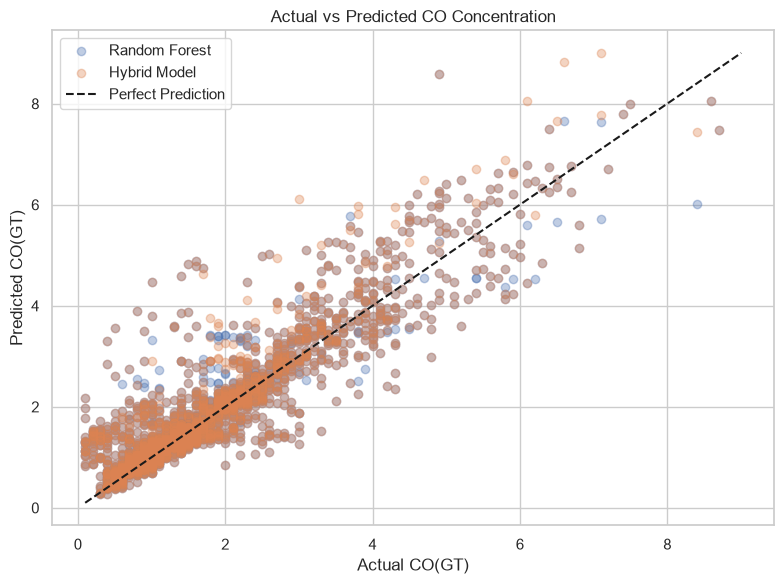

In [55]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    y_test, test_predictions,
    alpha=0.35, label="Random Forest"
)

ax.scatter(
    y_test, hybrid_test_predictions,
    alpha=0.35, label="Hybrid Model"
)

limits = [
    min(y_test.min(), test_predictions.min(),
        hybrid_test_predictions.min()),
    max(y_test.max(), test_predictions.max(),
        hybrid_test_predictions.max())
]

ax.plot(limits, limits, "k--", label="Perfect Prediction")

ax.set(
    title="Actual vs Predicted CO Concentration",
    xlabel="Actual CO(GT)",
    ylabel="Predicted CO(GT)"
)

ax.legend()
plt.tight_layout()
plt.show()

## 9. Findings and Next Steps

### Final Model Evaluation — Key Findings

- Random Forest achieved the best overall performance on the final chronological test set (MAE = 0.413, RMSE = 0.644, R² = 0.780).
- The Hybrid Model improved validation performance but did not maintain its advantage on the independent test set (R² = 0.770).
- Both models generally follow the relationship between actual and predicted CO concentrations, although prediction errors increase for some observations.
- The visualization suggests a tendency to overestimate low CO concentrations and underestimate some high concentrations.
- Simultaneous missing sensor measurements remain a significant challenge, particularly when most input features are unavailable.
- The results demonstrate that a more complex modeling strategy does not necessarily provide better generalization.

**Conclusion:** Random Forest remains a strong, simpler reference model for CO concentration estimation. The Hybrid Model provides useful experimental findings but does not demonstrate a consistent performance advantage across evaluation periods.